In [7]:
# Assignment 3 - Machine Learning Fundamentals
# Adam Lee
# COMP5600
# 10/23/26

# import libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    calinski_harabasz_score,
    silhouette_score,
    davies_bouldin_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    mean_squared_error,
    r2_score
)
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from google.colab import files

SEED = 42




In [8]:
## Part 1 — The Mystery Groups: Life on Kepler-186f
## inspect dataset
creatures = pd.read_csv(
    csv_path('/content/part1_kepler_creatures.csv')
)

features1 = (
    creatures.drop(columns=['creature_id'])
    .select_dtypes(include='number')
    .columns.tolist()
)

X1 = creatures[features1]

print('Dataset shape:', creatures.shape)
print('\nMissing values:')
print(creatures.isna().sum())

print('\nFeature summary:')
display(X1.describe().T)

print('\nNumeric features:')
print(features1)


Dataset shape: (600, 7)

Missing values:
creature_id      0
height_cm        0
mass_g           0
arm_span_cm      0
max_speed_mps    0
body_temp_c      0
sleep_hours      0
dtype: int64

Feature summary:


,count,mean,std,min,25%,50%,75%,max
height_cm,600.0,118.827421,29.205228,47.618681,100.610816,119.444980,134.958362,190.608887
mass_g,600.0,8834.557099,3904.015122,1217.844277,5543.309127,8587.895386,11795.958412,18465.465172
arm_span_cm,600.0,102.438525,20.208703,48.968804,84.800095,103.900376,119.442220,147.752109
max_speed_mps,600.0,6.361639,1.460158,2.663335,5.319009,6.436432,7.350206,10.368123
body_temp_c,600.0,31.091521,1.818792,26.761816,29.638688,31.202759,32.489022,35.758926
sleep_hours,600.0,8.007445,1.331294,4.623057,6.888853,8.099333,9.041535,10.879297



Numeric features:
['height_cm', 'mass_g', 'arm_span_cm', 'max_speed_mps', 'body_temp_c', 'sleep_hours']


Original feature results:


,scale,K,CH,Silhouette,DB
0,Original,2,1657.347,0.620,0.506
1,Original,3,2028.259,0.573,0.527
2,Original,4,2416.819,0.549,0.533
3,Original,5,2871.844,0.555,0.515
4,Original,6,3351.256,0.556,0.517
5,Original,7,3611.451,0.535,0.525
6,Original,8,4013.942,0.545,0.515
7,Original,9,4497.693,0.554,0.488
8,Original,10,5277.594,0.561,0.483


Standardized feature results:


,scale,K,CH,Silhouette,DB
0,Standardized,2,571.020,0.396,0.986
1,Standardized,3,479.189,0.343,1.109
2,Standardized,4,500.925,0.368,1.027
3,Standardized,5,552.684,0.417,0.907
4,Standardized,6,483.050,0.377,1.098
5,Standardized,7,431.252,0.343,1.268
6,Standardized,8,398.552,0.318,1.335
7,Standardized,9,377.114,0.271,1.441
8,Standardized,10,356.875,0.226,1.527


/tmp/ipykernel_4755/1666065228.py:57: MatplotlibDeprecationWarning: Passing label as a length 9 sequence when plotting a single dataset is deprecated in Matplotlib 3.9 and will error in 3.11.  To keep the current behavior, cast the sequence to string before passing.
  ax.plot(


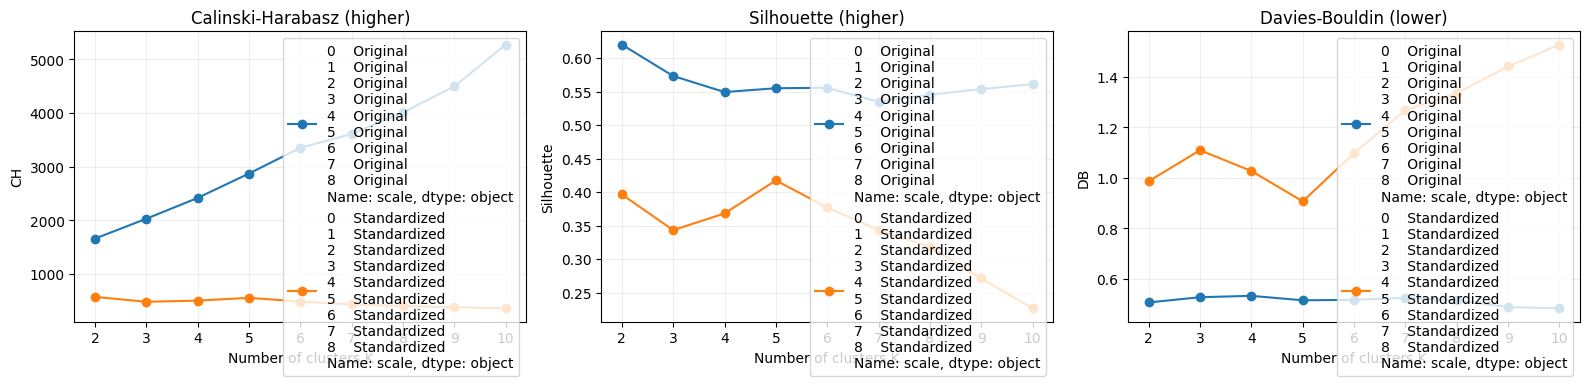

Top original K choices:


,scale,K,CH,Silhouette,DB,rank_sum
8,Original,10,5277.594,0.561,0.483,5.0
7,Original,9,4497.693,0.554,0.488,10.0
0,Original,2,1657.347,0.620,0.506,13.0
4,Original,6,3351.256,0.556,0.517,15.0
3,Original,5,2871.844,0.555,0.515,15.0


Top standardized K choices:


,scale,K,CH,Silhouette,DB,rank_sum
3,Standardized,5,552.684,0.417,0.907,4.0
0,Standardized,2,571.020,0.396,0.986,5.0
2,Standardized,4,500.925,0.368,1.027,10.0
4,Standardized,6,483.050,0.377,1.098,11.0
1,Standardized,3,479.189,0.343,1.109,16.0


In [9]:
# k-means evaluation and graphs


def evaluate_kmeans(X, label):
    records = []

    for k in range(2, 11):
        km = KMeans(
            n_clusters=k,
            n_init=20,
            random_state=SEED
        )

        groups = km.fit_predict(X)

        records.append({
            'scale': label,
            'K': k,
            'CH': calinski_harabasz_score(X, groups),
            'Silhouette': silhouette_score(X, groups),
            'DB': davies_bouldin_score(X, groups)
        })

    return pd.DataFrame(records)


scaler1 = StandardScaler()

X1_scaled = pd.DataFrame(
    scaler1.fit_transform(X1),
    columns=features1,
    index=X1.index
)

raw_scores = evaluate_kmeans(X1, 'Original')
scaled_scores = evaluate_kmeans(
    X1_scaled, 'Standardized'
)

print('Original feature results:')
display(raw_scores.round(3))

print('Standardized feature results:')
display(scaled_scores.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

metrics = ['CH', 'Silhouette', 'DB']
titles = [
    'Calinski-Harabasz (higher)',
    'Silhouette (higher)',
    'Davies-Bouldin (lower)'
]

for ax, metric, title in zip(axes, metrics, titles):
    for df in [raw_scores, scaled_scores]:
        ax.plot(
            df['K'],
            df[metric],
            marker='o',
            label=df['scale']
        )

    ax.set_title(title)
    ax.set_xlabel('Number of clusters K')
    ax.set_ylabel(metric)
    ax.set_xticks(range(2, 11))
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


def rank_metrics(df):
    temp = df.copy()

    temp['rank_sum'] = (
        temp.CH.rank(ascending=False)
        + temp.Silhouette.rank(ascending=False)
        + temp.DB.rank(ascending=True)
    )

    return temp.sort_values(
        ['rank_sum', 'Silhouette'],
        ascending=[True, False]
    )


print('Top original K choices:')
display(rank_metrics(raw_scores).head(5).round(3))

print('Top standardized K choices:')
display(rank_metrics(scaled_scores).head(5).round(3))


Preferred K (original): {'CH': 10, 'Silhouette': 2, 'DB': 10}
Preferred K (standardized): {'CH': 2, 'Silhouette': 5, 'DB': 5}
Final selected K: 5

Cluster sizes:


,count
cluster,
0,114
1,114
2,117
3,132
4,123



Cluster means:


,height_cm,mass_g,arm_span_cm,max_speed_mps,body_temp_c,sleep_hours
cluster,,,,,,
0,122.96,6377.36,107.19,8.22,32.01,7.19
1,115.91,11372.06,87.07,6.62,31.60,8.53
2,162.18,14139.60,127.69,5.74,29.14,9.70
3,78.71,4154.64,78.46,6.90,33.09,6.36
4,119.52,8736.22,113.99,4.40,29.49,8.43



Cluster medians:


,height_cm,mass_g,arm_span_cm,max_speed_mps,body_temp_c,sleep_hours
cluster,,,,,,
0,123.68,6376.34,106.62,8.19,32.11,7.22
1,115.89,11386.28,87.61,6.66,31.71,8.56
2,161.28,14206.31,127.96,5.82,29.26,9.70
3,78.47,3985.81,78.74,6.90,33.08,6.38
4,119.46,8664.16,113.85,4.44,29.59,8.40



Cluster nicknames:
{0: 'High max speed mps / Low mass g', 1: 'Low arm span cm / High mass g', 2: 'High height cm / High mass g', 3: 'Low height cm / Low sleep hours', 4: 'Low max speed mps / Low body temp c'}


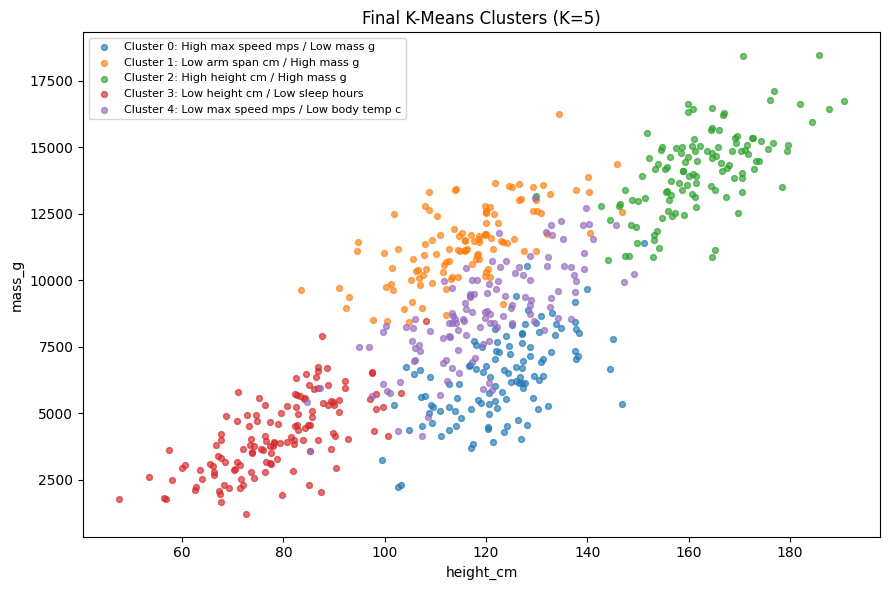

Plotted features: height_cm mass_g
Final silhouette score: 0.417


In [10]:
# Cluster selection/ final clustering model


best_raw = {
    m: int(raw_scores.loc[
        raw_scores[m].idxmin() if m == 'DB'
        else raw_scores[m].idxmax(), 'K'
    ])
    for m in ['CH', 'Silhouette', 'DB']
}

best_scaled = {
    m: int(scaled_scores.loc[
        scaled_scores[m].idxmin() if m == 'DB'
        else scaled_scores[m].idxmax(), 'K'
    ])
    for m in ['CH', 'Silhouette', 'DB']
}

FINAL_K = int(rank_metrics(scaled_scores).iloc[0]['K'])

print('Preferred K (original):', best_raw)
print('Preferred K (standardized):', best_scaled)
print('Final selected K:', FINAL_K)

final_km = KMeans(
    n_clusters=FINAL_K,
    n_init=20,
    random_state=SEED
)

creatures['cluster'] = final_km.fit_predict(X1_scaled)

cluster_means = creatures.groupby('cluster')[features1].mean()
cluster_medians = creatures.groupby('cluster')[features1].median()
cluster_sizes = creatures.groupby('cluster').size()

print('\nCluster sizes:')
display(cluster_sizes.rename('count').to_frame())

print('\nCluster means:')
display(cluster_means.round(2))

print('\nCluster medians:')
display(cluster_medians.round(2))

# Generate descriptive cluster nicknames
z_means = (
    (cluster_means - X1.mean())
    / X1.std(ddof=0)
)

name_map = {}

for cluster, row in z_means.iterrows():
    top = row.abs().sort_values(
        ascending=False
    ).index[:2]

    name_map[cluster] = ' / '.join(
        ('High ' if row[f] > 0 else 'Low ')
        + f.replace('_', ' ')
        for f in top
    )

print('\nCluster nicknames:')
print(name_map)

# Select two informative features
centroid_variance = (
    X1_scaled.assign(cluster=creatures.cluster)
    .groupby('cluster')[features1]
    .mean()
    .var()
    .sort_values(ascending=False)
)

f_x, f_y = centroid_variance.index[:2]

plt.figure(figsize=(9, 6))

for c in sorted(creatures.cluster.unique()):
    d = creatures[creatures.cluster == c]

    plt.scatter(
        d[f_x],
        d[f_y],
        s=18,
        alpha=0.65,
        label=f'Cluster {c}: {name_map[c]}'
    )

plt.xlabel(f_x)
plt.ylabel(f_y)
plt.title(f'Final K-Means Clusters (K={FINAL_K})')
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

print('Plotted features:', f_x, f_y)

print(
    'Final silhouette score:',
    round(
        silhouette_score(X1_scaled, creatures.cluster),
        3
    )
)



### Part 1 Reflection

**1. What value of K did you choose, and what evidence supports your choice?**

I selected K = 5 using the standardized features. This choice is supported by the silhouette score, approximately 0.417 and the Davies-Bouldin index, approximately 0.907, which are the best values among the standardized models. Although the Calinski-Harabasz index favors K = 2, the combined evidence supports five clusters.

**2. Did the clustering metrics agree? If not, how did you resolve the disagreement?**

The metrics do not agree completely. The Calinski-Harabasz index favored K = 2, while the silhouette and Davies-Bouldin metrics favored K = 5. I selected K = 5 because two metrics supported it and the resulting clusters showed meaningful differences in their features.

**3. How did standardization change your results? Why does scaling matter for K-Means?**

Standardization changed the clustering scores and the preferred number of clusters. K-Means uses Euclidean distance, meaning features with larger numerical values can dominate the results. Standardizing the features gives each measurement a more comparable influence on clustering.

**4. Suppose a biologist tells you there are exactly six species. Should you automatically set K = 6? Why or why not?**

No, because biological species and mathematical clusters are not necessarily the same. Six species would be a useful hypothesis, but I would compare K = 6 with the clustering metrics and biological evidence before accepting it.

**5. What evidence would make you skeptical that the discovered groups represent real structure?**

I would be skeptical if the silhouette scores were very low, the clusters overlapped heavily, or the results changed dramatically with different random seeds. These observations would suggest that K-Means may be forcing artificial groups onto the data.

**6. Pick one discovered cluster. What makes it distinctive compared with the others?**

Cluster 3 stands out because it contains the smallest creatures, with an average height of 78.71 cm and mass of 4,154.64 g. These creatures also sleep approximately 6.36 hours, which is less than the other clusters. Their smaller body size and shorter sleep duration make them distinctive compared with the other groups.

**7. If you could collect one additional measurement from these creatures, what would you measure and why?**

I would collect genetic information or DNA-based similarity measurements. Genetic information could provide independent evidence of biological relationships and help determine whether the discovered clusters represent different species.


Dataset shape: (520, 8)


,count,mean,std,min,25%,50%,75%,max
distance_km,520.0,12.944260,7.049029,1.044662,6.842341,12.674816,19.024058,24.942112
payload_kg,520.0,9.242399,5.243937,0.027920,4.549285,9.819318,13.751229,17.983811
terrain_roughness,520.0,4.823790,2.917742,0.040640,2.337442,4.712539,7.254888,9.998568
battery_efficiency,520.0,0.739662,0.114690,0.551323,0.637919,0.733289,0.834549,0.949130
ambient_temp_c,520.0,13.990653,16.243658,-14.945980,0.252440,13.806396,28.535047,41.753196
paint_brightness,520.0,48.983732,29.826433,0.489561,21.368974,48.218386,76.339007,99.921408
energy_used_kwh,520.0,68.351952,22.641395,10.033479,50.549589,69.082689,83.502075,124.742550



Recovered coefficients:


,coefficient
intercept,20.024124
distance_km,2.588763
payload_kg,1.394104
terrain_roughness,3.764335
battery_efficiency,-26.428276
ambient_temp_c,0.216023
paint_brightness,0.006291



Recovered equation:
energy_used_kwh = 20.0241 + 2.5888 * distance_km + 1.3941 * payload_kg + 3.7643 * terrain_roughness - 26.4283 * battery_efficiency + 0.2160 * ambient_temp_c + 0.0063 * paint_brightness

Training MSE: 13.275434195631773
Training R-squared: 0.9736768463009635
Test MSE: 11.812421762257767
Test R-squared: 0.9781213055306102


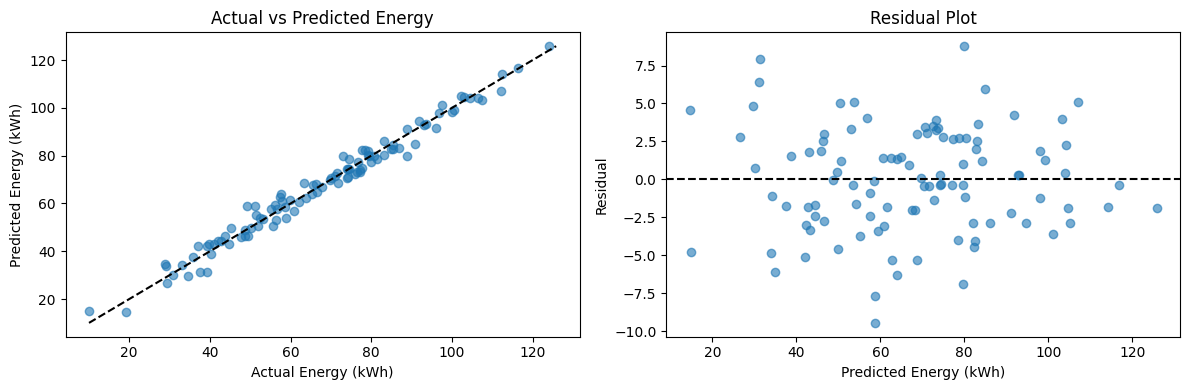


Residual mean: -0.03747735920910282
Residual standard deviation: 3.4533588402890567
Mean absolute error: 2.7947986863483085

Absolute effects per standard deviation:


,abs_effect_kwh_per_SD
distance_km,17.900725
terrain_roughness,10.971780
payload_kg,7.258941
ambient_temp_c,3.521045
battery_efficiency,3.022620
paint_brightness,0.187325


Smallest standardized effect: paint_brightness

Estimated hidden equation:
energy_used_kwh ≈ 20 + 2.6 * distance_km + 1.4 * payload_kg + 3.8 * terrain_roughness - 26.4 * battery_efficiency + 0.2 * ambient_temp_c


In [11]:
## Part 2 — Recover the Hidden Law: Rover Energy Use

rover = pd.read_csv(csv_path('/content/part2_rover_energy.csv'))

features2 = [
    c for c in rover.columns
    if c not in ['mission_id', 'energy_used_kwh']
]

print('Dataset shape:', rover.shape)
display(rover[features2 + ['energy_used_kwh']].describe().T)

# Split the data into 80% training and 20% testing
rng = np.random.default_rng(42)
indices = rng.permutation(len(rover))
split = int(0.8 * len(rover))

train_idx = indices[:split]
test_idx = indices[split:]

A_train = rover.iloc[train_idx][features2].to_numpy()
A_test = rover.iloc[test_idx][features2].to_numpy()

y_train = rover.iloc[train_idx]['energy_used_kwh'].to_numpy()
y_test = rover.iloc[test_idx]['energy_used_kwh'].to_numpy()

# Build design matrices with an intercept column
X_train = np.column_stack([
    np.ones(len(A_train)),
    A_train
])

X_test = np.column_stack([
    np.ones(len(A_test)),
    A_test
])

# Calculate coefficients using the normal equation
beta = (
    np.linalg.pinv(X_train.T @ X_train)
    @ X_train.T
    @ y_train
)

coefficients = pd.Series(
    beta,
    index=['intercept'] + features2,
    name='coefficient'
)

print('\nRecovered coefficients:')
display(coefficients.to_frame())

# Print the recovered equation
equation = f'energy_used_kwh = {beta[0]:.4f}'

for f, v in zip(features2, beta[1:]):
    sign = '+' if v >= 0 else '-'
    equation += f' {sign} {abs(v):.4f} * {f}'

print('\nRecovered equation:')
print(equation)

# Generate predictions
train_pred = X_train @ beta
y_pred = X_test @ beta

# Calculate MSE and R-squared manually
train_mse = np.mean((y_train - train_pred) ** 2)
test_mse = np.mean((y_test - y_pred) ** 2)

train_r2 = 1 - (
    np.sum((y_train - train_pred) ** 2)
    / np.sum((y_train - np.mean(y_train)) ** 2)
)

test_r2 = 1 - (
    np.sum((y_test - y_pred) ** 2)
    / np.sum((y_test - np.mean(y_test)) ** 2)
)

print('\nTraining MSE:', train_mse)
print('Training R-squared:', train_r2)
print('Test MSE:', test_mse)
print('Test R-squared:', test_r2)

# Examine prediction errors
residual = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(y_test, y_pred, alpha=0.6)

limits = [
    min(y_test.min(), y_pred.min()),
    max(y_test.max(), y_pred.max())
]

axes[0].plot(limits, limits, 'k--')
axes[0].set_xlabel('Actual Energy (kWh)')
axes[0].set_ylabel('Predicted Energy (kWh)')
axes[0].set_title('Actual vs Predicted Energy')

axes[1].scatter(y_pred, residual, alpha=0.6)
axes[1].axhline(0, color='black', linestyle='--')
axes[1].set_xlabel('Predicted Energy (kWh)')
axes[1].set_ylabel('Residual')
axes[1].set_title('Residual Plot')

plt.tight_layout()
plt.show()

print('\nResidual mean:', residual.mean())
print('Residual standard deviation:', residual.std(ddof=1))
print('Mean absolute error:', np.abs(residual).mean())

# Compare feature effects using their standard deviations
standardized_effect = pd.Series(
    beta[1:] * rover.iloc[train_idx][features2]
    .std(ddof=0).to_numpy(),
    index=features2
)

print('\nAbsolute effects per standard deviation:')
display(
    standardized_effect.abs()
    .sort_values(ascending=False)
    .rename('abs_effect_kwh_per_SD')
    .to_frame()
)

print(
    'Smallest standardized effect:',
    standardized_effect.abs().idxmin()
)

# Estimate the original equation with rounded coefficients
rounded_beta = np.round(beta, 1)

guess = f'energy_used_kwh ≈ {rounded_beta[0]:g}'

for f, v in zip(features2, rounded_beta[1:]):
    if abs(v) >= 0.05:
        sign = '+' if v >= 0 else '-'
        guess += f' {sign} {abs(v):g} * {f}'

print('\nEstimated hidden equation:')
print(guess)





### Part 2 Reflection

**1. What equation did your model recover?**

The model recovered the following equation:

Energy = 20.0241 + 2.5888(Distance) + 1.3941(Payload) + 3.7643(Terrain Roughness) − 26.4283(Battery Efficiency) + 0.2160(Ambient Temperature) + 0.0063(Paint Brightness).

The model achieved a **test R^2** of 0.9781 and **MSE** of 11.8124, indicating that it explains approximately 97.81% of the variation in test energy consumption.

**2. Which variables appear to have the strongest effects on energy usage? Explain the signs and magnitudes in context.**

Distance, terrain roughness, and payload had the strongest standardized effects, contributing approximately 17.90, 10.97, and 7.26 kWh per standard deviation. Their positive coefficients indicate that traveling farther, carrying more weight, and navigating rougher terrain increase energy consumption. Battery efficiency has a negative coefficient of -26.4283, meaning greater efficiency reduces predicted energy usage when other variables remain constant.

**3. Does any variable appear irrelevant? What evidence led you to that conclusion?**

Paint brightness appears to contribute very little to energy consumption. Its coefficient is approximately 0.0063, and its standardized effect is only 0.1873 kWh, the smallest among all predictors. This suggests that paint brightness contributes very little to the linear model.

**4. Why would your recovered coefficients not exactly equal the hidden coefficients?**

The dataset contains measurement noise, which affects the estimated coefficients. Differences can also result from the limited number of observations and correlations between the predictors.

**5. What would it mean if your model obtained R-squared = 1.0 on both training and unseen test data? Would that always be realistic?**

An R^2 value of 1.0 would mean the model perfectly predicts the observed energy values in both datasets. This would be unusual for real-world measurements because noise and unpredictable factors usually affect the results. It could occur with perfectly generated synthetic data.

**6. What assumptions are you making when you represent rover energy consumption with a linear model?**

The model assumes energy consumption can be approximated by a linear combination of the predictors. Each variable contributes a constant amount per unit change when the others are held fixed. The model does not directly account for nonlinear relationships or interactions.

**7. Could a variable have a coefficient near zero and still be useful in a more complicated nonlinear model?**

Yes. A variable might have a weak linear effect but still influence energy consumption through nonlinear relationships or interactions. A nonlinear model could potentially identify patterns that linear regression misses.

**Estimated Original Equation**

Energy ≈ 20 + 2.6(Distance) + 1.4(Payload) + 3.8(Terrain Roughness) − 26.4(Battery Efficiency) + 0.2(Ambient Temperature).

#NOTES
I rounded the coefficients to one decimal place because the dataset contains measurement noise and the original equation is believed to be simple. Paint brightness was omitted because its standardized effect was extremely small compared with the other predictors.



In [12]:
## Part 3 — Choose Your AI: Alien Fruit Safety


fruit = pd.read_csv(
    csv_path('/content/part3_alien_fruit.csv')
)

features3 = [
    c for c in fruit.columns
    if c not in ['fruit_id', 'class']
]

print('Dataset shape:', fruit.shape)

counts = fruit['class'].value_counts()

display(pd.DataFrame({
    'count': counts,
    'fraction': counts / len(fruit)
}))

print('\nMissing values:')
print(fruit.isna().sum())

print(
    '\nClass balance:',
    'approximately balanced'
    if abs(counts.iloc[0] / len(fruit) - 0.5) < 0.1
    else 'imbalanced'
)

X3 = fruit[features3]
y3 = fruit['class']

# Stratified train/test split
Xtr, Xte, ytr, yte = train_test_split(
    X3,
    y3,
    test_size=0.2,
    stratify=y3,
    random_state=SEED
)

print('\nTraining class proportions:')
display(ytr.value_counts(normalize=True))

print('\nTest class proportions:')
display(yte.value_counts(normalize=True))


Dataset shape: (900, 9)


,count,fraction
class,,
safe,629,0.698889
toxic,271,0.301111



Missing values:
fruit_id          0
mass_g            0
acidity_ph        0
sugar_brix        0
hardness          0
surface_temp_c    0
radiation_cpm     0
stripe_score      0
class             0
dtype: int64

Class balance: imbalanced

Training class proportions:


,proportion
class,
safe,0.698611
toxic,0.301389



Test class proportions:


,proportion
class,
safe,0.7
toxic,0.3


kNN validation results:


,scaled,K,toxic_recall_cv,recall_sd,macro_recall_cv
0,False,1,0.489,0.056,0.645
1,False,3,0.456,0.051,0.647
2,False,5,0.456,0.047,0.665
3,False,7,0.438,0.058,0.674
4,False,9,0.401,0.075,0.659
5,False,11,0.401,0.082,0.665
6,False,15,0.397,0.078,0.663
7,False,21,0.387,0.044,0.670
8,True,1,0.456,0.031,0.609
9,True,3,0.442,0.028,0.645


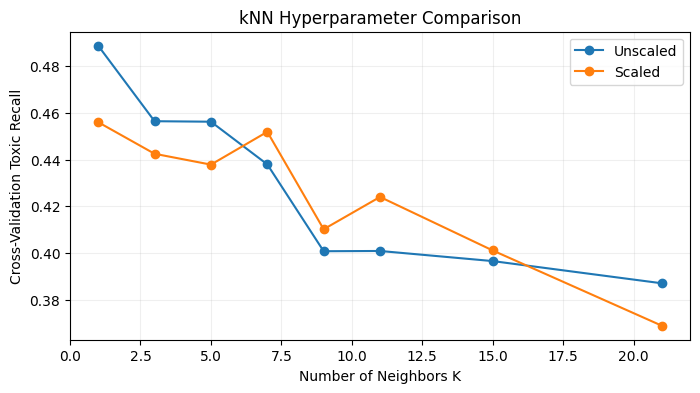

Selected kNN K: 1
Standardized: False

Final classifier comparison:


,Accuracy,Toxic precision,Toxic recall,Toxic F1,Toxic predicted safe
Model,,,,,
Logistic Regression,0.839,0.745,0.704,0.724,16
Gaussian Naive Bayes,0.844,0.842,0.593,0.696,22
kNN,0.711,0.519,0.500,0.509,27


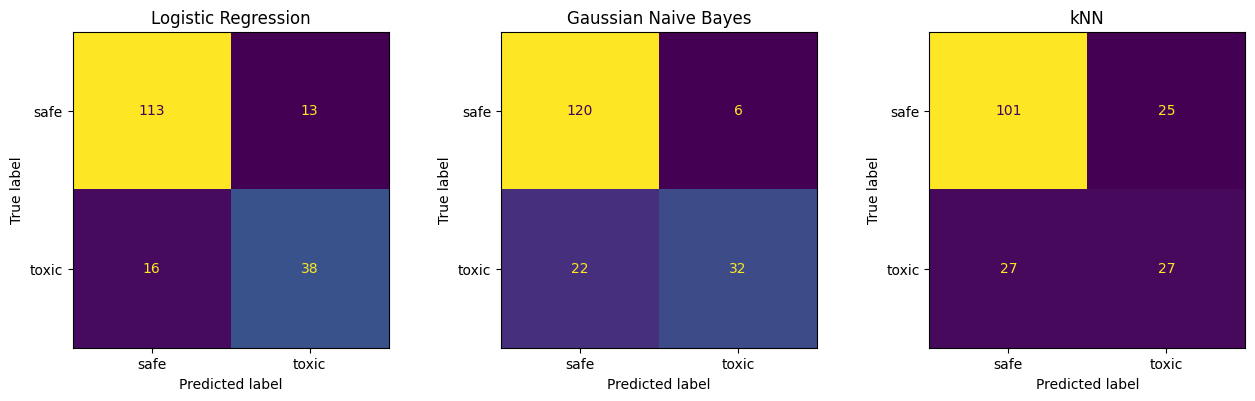

Highest test accuracy: Gaussian Naive Bayes
Recommended deployment model: Logistic Regression

Disagreement example: F-0369
Actual class: safe


,fruit_id,mass_g,acidity_ph,sugar_brix,hardness,surface_temp_c,radiation_cpm,stripe_score,class
371,F-0369,140.556833,7.681484,10.256448,79.195452,26.808713,36.41921,25.605367,safe


,Logistic Regression,Gaussian Naive Bayes,kNN
371,toxic,safe,toxic



Feature percentiles:
{'mass_g': np.float64(18.5), 'acidity_ph': np.float64(90.8), 'sugar_brix': np.float64(35.6), 'hardness': np.float64(90.4), 'surface_temp_c': np.float64(64.9), 'radiation_cpm': np.float64(54.7), 'stripe_score': np.float64(25.1)}


In [13]:

# Investigate kNN with and without standardization
ks = [1, 3, 5, 7, 9, 11, 15, 21]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

rows = []

for scaled in [False, True]:
    for k in ks:

        if scaled:
            clf = make_pipeline(
                StandardScaler(),
                KNeighborsClassifier(n_neighbors=k)
            )
        else:
            clf = KNeighborsClassifier(n_neighbors=k)

        # Validation recall for toxic fruit
        toxic_scores = cross_val_score(
            clf,
            Xtr,
            (ytr == 'toxic').astype(int),
            cv=cv,
            scoring='recall'
        )

        macro_scores = cross_val_score(
            clf,
            Xtr,
            ytr,
            cv=cv,
            scoring='recall_macro'
        )

        rows.append({
            'scaled': scaled,
            'K': k,
            'toxic_recall_cv': toxic_scores.mean(),
            'recall_sd': toxic_scores.std(),
            'macro_recall_cv': macro_scores.mean()
        })

cv_results = pd.DataFrame(rows)

print('kNN validation results:')
display(cv_results.round(3))

# Plot kNN performance
plt.figure(figsize=(8, 4))

for scaled, group in cv_results.groupby('scaled'):
    plt.plot(
        group.K,
        group.toxic_recall_cv,
        marker='o',
        label='Scaled' if scaled else 'Unscaled'
    )

plt.xlabel('Number of Neighbors K')
plt.ylabel('Cross-Validation Toxic Recall')
plt.title('kNN Hyperparameter Comparison')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

# Choose best kNN using training validation only
chosen = cv_results.sort_values(
    ['toxic_recall_cv', 'macro_recall_cv', 'K'],
    ascending=[False, False, True]
).iloc[0]

BEST_K = int(chosen.K)
BEST_SCALED = bool(chosen.scaled)

print('Selected kNN K:', BEST_K)
print('Standardized:', BEST_SCALED)

# Train three final classifiers
models = {
    'Logistic Regression': make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=2000,
            random_state=SEED
        )
    ),
    'Gaussian Naive Bayes': GaussianNB(),
    'kNN': (
        make_pipeline(
            StandardScaler(),
            KNeighborsClassifier(n_neighbors=BEST_K)
        )
        if BEST_SCALED
        else KNeighborsClassifier(n_neighbors=BEST_K)
    )
}

preds = {}
records = []

for name, model in models.items():
    model.fit(Xtr, ytr)

    yp = model.predict(Xte)

    preds[name] = pd.Series(yp, index=yte.index)

    records.append({
        'Model': name,
        'Accuracy': accuracy_score(yte, yp),
        'Toxic precision': precision_score(
            yte, yp, pos_label='toxic'
        ),
        'Toxic recall': recall_score(
            yte, yp, pos_label='toxic'
        ),
        'Toxic F1': f1_score(
            yte, yp, pos_label='toxic'
        ),
        'Toxic predicted safe': int(
            ((yte == 'toxic') & (yp == 'safe')).sum()
        )
    })

results = pd.DataFrame(records).set_index('Model')

print('\nFinal classifier comparison:')
display(results.round(3))

# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, (name, yp) in zip(axes, preds.items()):
    cm = confusion_matrix(
        yte,
        yp,
        labels=['safe', 'toxic']
    )

    ConfusionMatrixDisplay(
        cm,
        display_labels=['safe', 'toxic']
    ).plot(ax=ax, colorbar=False)

    ax.set_title(name)

plt.tight_layout()
plt.show()

# Deployment recommendation
deployment = results.sort_values(
    ['Toxic predicted safe', 'Toxic F1', 'Accuracy'],
    ascending=[True, False, False]
).index[0]

print(
    'Highest test accuracy:',
    results.Accuracy.idxmax()
)

print(
    'Recommended deployment model:',
    deployment
)

# Find a disagreement example
prediction_table = pd.DataFrame(preds)

disagree = prediction_table.nunique(axis=1) > 1

if disagree.any():
    idx = prediction_table.index[disagree][0]

    print(
        '\nDisagreement example:',
        fruit.loc[idx, 'fruit_id']
    )

    print('Actual class:', fruit.loc[idx, 'class'])

    display(
        fruit.loc[
            [idx],
            ['fruit_id'] + features3 + ['class']
        ]
    )

    display(prediction_table.loc[[idx]])

    print('\nFeature percentiles:')
    print({
        f: round(
            100 * (Xtr[f] < fruit.loc[idx, f]).mean(),
            1
        )
        for f in features3
    })
else:
    print('No classifier disagreement found.')



### Part 3 Reflection

**1. Which classifier had the highest overall accuracy?**

Gaussian Naive Bayes achieved the highest overall accuracy of 0.844, or 84.4%. Logistic Regression followed closely with an accuracy of 83.9%, while kNN achieved 71.1%.

**2. Which classifier would you deploy? Your answer does not have to be the most accurate classifier.**

I would deploy Logistic Regression because it made fewer dangerous mistakes when predicting toxic fruit. It incorrectly classified 16 toxic fruits as safe, compared with 22 for Gaussian Naive Bayes and 27 for kNN. Since the colony prioritizes safety, reducing these mistakes is more important than achieving the highest overall accuracy.

**3. In this problem, which error is more costly: a false positive or a false negative? Explain using the meaning of the classes.**

A false negative is more costly because it occurs when toxic fruit is incorrectly predicted as safe. This could allow dangerous fruit into the colony's food supply. A false positive would reject a safe fruit, which is inconvenient but less dangerous.

**4. How should that error cost affect which evaluation metric you prioritize?**

I would prioritize recall for the toxic class because it measures how many actual toxic fruits are correctly identified. High toxic recall means fewer dangerous fruits are incorrectly classified as safe. I would also examine the confusion matrix and the number of false negatives rather than relying only on accuracy.

**5. How did K affect kNN performance? How did standardization affect kNN? Why?**

Changing K affected how many neighboring examples contributed to each classification. Smaller K values made predictions more sensitive to individual nearby observations, while larger K values produced smoother decisions. Standardization changed the distances between fruit observations because features were measured on different scales. The validation results selected K = 1 without standardization are based on toxic-class recall.

**6. What simplifying assumption does Gaussian Naive Bayes make about the features?**

Gaussian Naive Bayes assumes that features are conditionally independent given the class. It assumes that each feature follows a Gaussian distribution within a certain class. These assumptions simplify the calculation of class probabilities.

**7. Does Naive Bayes necessarily fail when its assumptions are not perfectly true? Explain from your results.**

No. Gaussian Naive Bayes can still perform well even when its assumptions are not perfectly satisfied. In this experiment, it achieved the highest overall accuracy of 84.4%. This demonstrates that simplified assumptions can still produce useful predictions.

**8. Logistic Regression first produces a probability and then turns it into a class decision. How could changing the decision threshold affect safety and false alarms?**

Lowering the threshold for predicting toxic fruit would generally increase toxic recall and reduce the number of dangerous fruits classified as safe. However, it could also increase false alarms by labeling more safe fruits as toxic. Raising the threshold would generally have the opposite effect.

**9. Why might different classifiers disagree on the same fruit even though they were trained on the same data?**

Different classifiers use different approaches to identify patterns. For example, fruit F-0369 was actually safe, but Logistic Regression and kNN predicted toxic while Gaussian Naive Bayes predicted safe. Its acidity pH of 7.68 and hardness of 79.20 were both around the 90th percentile of the training data, making it an unusual example that different models interpreted differently.

**10. If you were allowed to collect one new sensor measurement, what would you add and why?**

I would add a sensor that directly measures toxin concentration. This would provide more direct information about whether a fruit is dangerous rather than relying only on indirect physical or chemical measurements. It could improve toxic-fruit detection and reduce false negatives.
